In [ ]:
!pip install -q fiftyone
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import random, shutil, csv
from pathlib import Path
import fiftyone as fo
import fiftyone.zoo as foz
from fiftyone import ViewField as F

SEED = 51
random.seed(SEED)

OUT = Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset")
for split in ["train", "val", "test"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

# master class: (COCO class names to pull from, target number of images)
# door is not in COCO, so it has no entry and is skipped.
GROUPS = {
    "person":        (["person"], 2000),
    "two_wheeler":   (["bicycle", "motorcycle"], 1500),
    "car":           (["car"], 1500),
    "large_vehicle": (["bus", "truck"], 1000),
    "large_animal":  (["cow", "horse"], 400),
    "dog":           (["dog"], 600),
    "bench":         (["bench"], 400),
    "chair":         (["chair"], 800),
    "sports_ball":   (["sports ball"], 300),
    "traffic_light": (["traffic light"], 500),
}

COCO_TO_MASTER = {c: m for m, (cls, _) in GROUPS.items() for c in cls}
ALL_COCO = list(COCO_TO_MASTER)
MASTER = [m for m, (cls, _) in GROUPS.items() if cls]   # class IDs follow this order

# Download a pool of COCO train images that contain at least one target class
POOL_NAME = "coco_hazard_pool"
if fo.dataset_exists(POOL_NAME):
    fo.delete_dataset(POOL_NAME)

pool = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    label_types=["detections"],
    classes=ALL_COCO,
    only_matching=True,
    max_samples=15000,        # raise this if a class comes up short below
    shuffle=True,
    seed=SEED,
    dataset_name=POOL_NAME,
)

# Pick images per group, capped at each group's target
selected = set()
for master, (coco_classes, target) in GROUPS.items():
    if not coco_classes:
        continue
    matches = pool.match_labels(filter=F("label").is_in(coco_classes), fields="ground_truth")
    chosen = matches.shuffle(seed=SEED).limit(target)
    ids = chosen.values("id")
    selected.update(ids)
    flag = "" if len(ids) >= target else "  <-- SHORT, raise max_samples"
    print(f"{master:14s} selected {len(ids):5d} / target {target}{flag}")

print("Total unique images:", len(selected))

# Split randomly by image (COCO images are independent, not video frames)
ids = list(selected)
random.shuffle(ids)
n = len(ids)
n_train, n_val = int(0.70 * n), int(0.15 * n)
split_of = {}
for i, sid in enumerate(ids):
    split_of[sid] = "train" if i < n_train else ("val" if i < n_train + n_val else "test")

# Copy images and write YOLO labels, keeping only the master classes
final = pool.select(ids)
manifest_rows = []
instance_counts = {s: {m: 0 for m in MASTER} for s in ["train", "val", "test"]}

for sample in final.iter_samples(progress=True):
    split = split_of[sample.id]
    fname = f"coco_{sample.id}"
    shutil.copy(sample.filepath, OUT / "images" / split / f"{fname}.jpg")

    lines, present = [], set()
    for det in sample.ground_truth.detections:
        master = COCO_TO_MASTER.get(det.label)
        if master not in MASTER:
            continue
        x, y, w, h = det.bounding_box        # relative [x, y, w, h]
        lines.append(f"{MASTER.index(master)} {x + w/2:.6f} {y + h/2:.6f} {w:.6f} {h:.6f}")
        present.add(master)
        instance_counts[split][master] += 1

    (OUT / "labels" / split / f"{fname}.txt").write_text("\n".join(lines) + "\n")
    manifest_rows.append({"file": f"{fname}.jpg", "split": split, "classes": ";".join(sorted(present))})

# Manifest, data.yaml, and source note
with open(OUT / "manifest.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["file", "split", "classes"])
    writer.writeheader()
    writer.writerows(manifest_rows)

names = "\n".join(f"  {i}: {m}" for i, m in enumerate(MASTER))
(OUT / "data.yaml").write_text(
    f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names}\n"
)

(OUT / "SOURCE.txt").write_text(
    "Source: COCO 2017 (cocodataset.org). Annotations CC BY 4.0. Images from Flickr under\n"
    "various licenses. Check commercial-use terms before shipping. Subset selected by "
    "class with seed 51.\n"
)

# Instance counts per class per split
print("\nInstance counts (boxes) per split:")
for m in MASTER:
    row = {s: instance_counts[s][m] for s in ["train", "val", "test"]}
    print(f"{m:14s} {row}")

INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/root/fiftyone/coco-2017/train' if necessary


Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


INFO:fiftyone.utils.coco:Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


12440 images found; downloading the remaining 2560


INFO:fiftyone.utils.coco:12440 images found; downloading the remaining 2560


 100% |████████████████| 2560/2560 [4.9m elapsed, 0s remaining, 8.9 images/s]      


... (10 outputs left out)

INFO:fiftyone.zoo.datasets:Dataset 'coco_hazard_pool' created


person         selected  2000 / target 2000
two_wheeler    selected  1121 / target 1500  <-- SHORT, raise max_samples
car            selected  1500 / target 1500
large_vehicle  selected  1000 / target 1000
large_animal   selected   400 / target 400
dog            selected   600 / target 600
bench          selected   400 / target 400
chair          selected   800 / target 800
sports_ball    selected   300 / target 300
traffic_light  selected   500 / target 500
Total unique images: 6037
 100% |███████████████| 6037/6037 [4.4m elapsed, 0s remaining, 18.1 samples/s]      


INFO:eta.core.utils: 100% |███████████████| 6037/6037 [4.4m elapsed, 0s remaining, 18.1 samples/s]      



Instance counts (boxes) per split:
person         {'train': 13985, 'val': 2571, 'test': 3038}
two_wheeler    {'train': 1868, 'val': 380, 'test': 498}
car            {'train': 4171, 'val': 931, 'test': 949}
large_vehicle  {'train': 1551, 'val': 274, 'test': 305}
large_animal   {'train': 1058, 'val': 178, 'test': 200}
dog            {'train': 509, 'val': 131, 'test': 116}
bench          {'train': 676, 'val': 119, 'test': 135}
chair          {'train': 1912, 'val': 404, 'test': 411}
sports_ball    {'train': 316, 'val': 74, 'test': 63}
traffic_light  {'train': 1249, 'val': 296, 'test': 342}


In [ ]:
!pip install -q ultralytics matplotlib pyyaml pandas

In [ ]:
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils.plotting import plot_labels

data = check_det_dataset(str(OUT / "data.yaml"))

print(data)

{'path': PosixPath('/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset'), 'train': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/images/train', 'val': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/images/val', 'test': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/images/test', 'names': {0: 'person', 1: 'two_wheeler', 2: 'car', 3: 'large_vehicle', 4: 'large_animal', 5: 'dog', 6: 'bench', 7: 'chair', 8: 'sports_ball', 9: 'traffic_light'}, 'yaml_file': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/data.yaml', 'nc': 10, 'channels': 3}


Total annotations: 38710
Total classes: 10


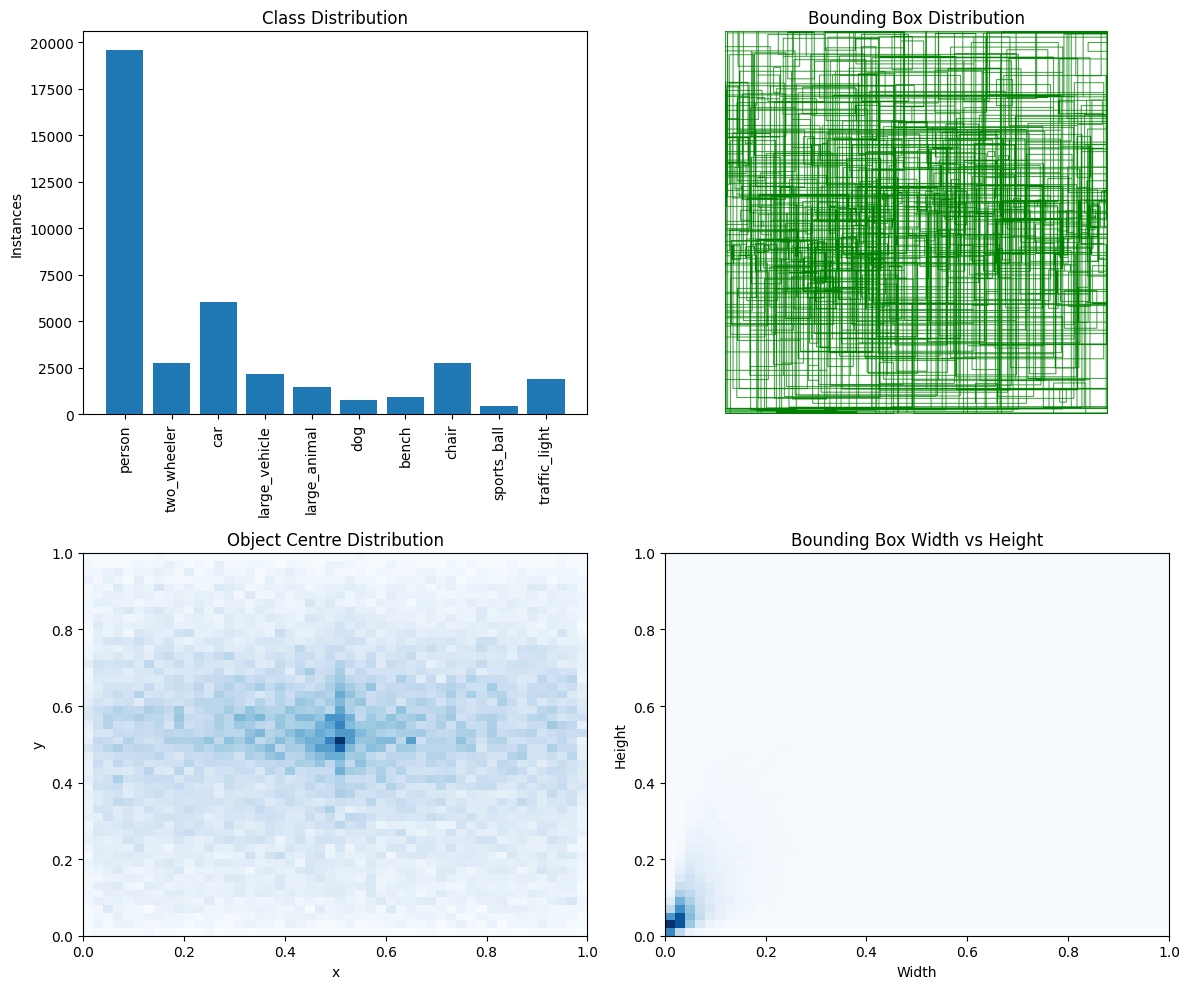

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/dataset_analysis.jpg


In [ ]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset")

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = DATASET_DIR

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)

In [ ]:
import random, shutil, csv
from pathlib import Path
from collections import Counter
import fiftyone as fo
import fiftyone.zoo as foz

SEED = 51
random.seed(SEED)

OUT = Path("/content/drive/MyDrive/Hazard_Dataset/raw_datasets/coco_dataset")
for split in ["train", "val", "test"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

# COCO class -> master class (names must match your final master list)
COCO_TO_MASTER = {
    "person": "person",
    "bicycle": "two_wheeler", "motorcycle": "two_wheeler",
    "car": "car",
    "bus": "large_vehicle", "truck": "large_vehicle",
    "cow": "large_animal", "horse": "large_animal",
    "dog": "dog",
    "bench": "bench",
    "chair": "chair",
    "sports ball": "sports_ball",
    "traffic light": "traffic_light",
}
MASTER = ["person", "two_wheeler", "car", "large_vehicle", "large_animal",
          "dog", "bench", "chair", "sports_ball", "traffic_light"]
MASTER_ID = {m: i for i, m in enumerate(MASTER)}

# Box targets (all splits combined) and hard caps.
# Target = what we aim for. Cap = never exceed.
TARGET = {"person": 5000, "two_wheeler": 2500, "car": 3000, "large_vehicle": 2000,
          "large_animal": 800, "dog": 1200, "bench": 1000, "chair": 2000,
          "sports_ball": 1000, "traffic_light": 2000}
CAP = {"person": 6000, "two_wheeler": 3000, "car": 4000, "large_vehicle": 2500,
       "large_animal": 1000, "dog": 1500, "bench": 1500, "chair": 3000,
       "sports_ball": 1500, "traffic_light": 2500}

# 1. One big pool with full labels for every class we keep
POOL_NAME = "coco_master_pool"
if fo.dataset_exists(POOL_NAME):
    fo.delete_dataset(POOL_NAME)

pool = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    label_types=["detections"],
    classes=list(COCO_TO_MASTER),
    only_matching=True,
    max_samples=40000,       # bigger pool so rare classes have enough candidates
    shuffle=True,
    seed=SEED,
    dataset_name=POOL_NAME,
)

# 2. Greedy selection by box count
def master_counts(sample):
    c = Counter()
    for d in sample.ground_truth.detections:
        m = COCO_TO_MASTER.get(d.label)
        if m:
            c[m] += 1
    return c

count = Counter()
chosen = []   # (sample, per-class counts)
for sample in pool.iter_samples(progress=True):
    c = master_counts(sample)
    if not c:
        continue
    if any(count[m] + n > CAP[m] for m, n in c.items()):   # would break a cap
        continue
    if not any(count[m] < TARGET[m] for m in c):           # adds nothing we still need
        continue
    chosen.append((sample, c))
    count.update(c)
    if all(count[m] >= TARGET[m] for m in MASTER):
        break

print("\nBox counts after selection (target / cap):")
for m in MASTER:
    flag = "" if count[m] >= TARGET[m] else "  <-- SHORT, raise pool size"
    print(f"{m:14s} {count[m]:6d}  ({TARGET[m]} / {CAP[m]}){flag}")
print("Images selected:", len(chosen))

# 3. Random split by image (COCO images are independent)
random.shuffle(chosen)
n = len(chosen)
n_tr, n_va = int(0.70 * n), int(0.15 * n)

manifest = []
split_counts = {s: Counter() for s in ["train", "val", "test"]}

for i, (sample, _) in enumerate(chosen):
    split = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")
    fname = f"coco_{sample.id}"
    shutil.copy(sample.filepath, OUT / "images" / split / f"{fname}.jpg")

    lines, present = [], set()
    for det in sample.ground_truth.detections:
        m = COCO_TO_MASTER.get(det.label)
        if not m:
            continue
        x, y, w, h = det.bounding_box
        lines.append(f"{MASTER_ID[m]} {x + w/2:.6f} {y + h/2:.6f} {w:.6f} {h:.6f}")
        present.add(m)
        split_counts[split][m] += 1

    (OUT / "labels" / split / f"{fname}.txt").write_text("\n".join(lines) + "\n")
    manifest.append({"file": f"{fname}.jpg", "split": split,
                     "classes": ";".join(sorted(present))})

# 4. Manifest, data.yaml, source note
with open(OUT / "manifest.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["file", "split", "classes"])
    w.writeheader()
    w.writerows(manifest)

names = "\n".join(f"  {i}: {m}" for i, m in enumerate(MASTER))
(OUT / "data.yaml").write_text(
    f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names}\n")

(OUT / "SOURCE.txt").write_text(
    "Source: COCO 2017 (cocodataset.org). Annotations CC BY 4.0. Images from Flickr under\n"
    "various licenses. Check commercial-use terms before shipping. Subset selected by\n"
    f"class with seed {SEED}, box targets and caps as in this script.\n")

# 5. Per-split box counts
print("\nBox counts per split:")
for m in MASTER:
    row = {s: split_counts[s][m] for s in ["train", "val", "test"]}
    print(f"{m:14s} {row}")

INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/root/fiftyone/coco-2017/train' if necessary


Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


INFO:fiftyone.utils.coco:Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


Sufficient images already downloaded


INFO:fiftyone.utils.coco:Sufficient images already downloaded


Existing download of split 'train' is sufficient


... (6 outputs left out)

INFO:fiftyone.zoo.datasets:Dataset 'coco_master_pool' created


 100% |█████████████| 40000/40000 [1.7m elapsed, 0s remaining, 547.1 samples/s]      


INFO:eta.core.utils: 100% |█████████████| 40000/40000 [1.7m elapsed, 0s remaining, 547.1 samples/s]      



Box counts after selection (target / cap):
person           6000  (5000 / 6000)
two_wheeler      1460  (2500 / 3000)  <-- SHORT, raise pool size
car              4000  (3000 / 4000)
large_vehicle    2003  (2000 / 2500)
large_animal     1000  (800 / 1000)
dog              1207  (1200 / 1500)
bench            1027  (1000 / 1500)
chair            2313  (2000 / 3000)
sports_ball       259  (1000 / 1500)  <-- SHORT, raise pool size
traffic_light    2019  (2000 / 2500)
Images selected: 5677

Box counts per split:
person         {'train': 4275, 'val': 954, 'test': 771}
two_wheeler    {'train': 1018, 'val': 208, 'test': 234}
car            {'train': 2727, 'val': 610, 'test': 663}
large_vehicle  {'train': 1418, 'val': 307, 'test': 278}
large_animal   {'train': 708, 'val': 161, 'test': 131}
dog            {'train': 844, 'val': 196, 'test': 167}
bench          {'train': 701, 'val': 127, 'test': 199}
chair          {'train': 1675, 'val': 298, 'test': 340}
sports_ball    {'train': 179, 'val': 39, 

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Total annotations: 32593
Total classes: 10


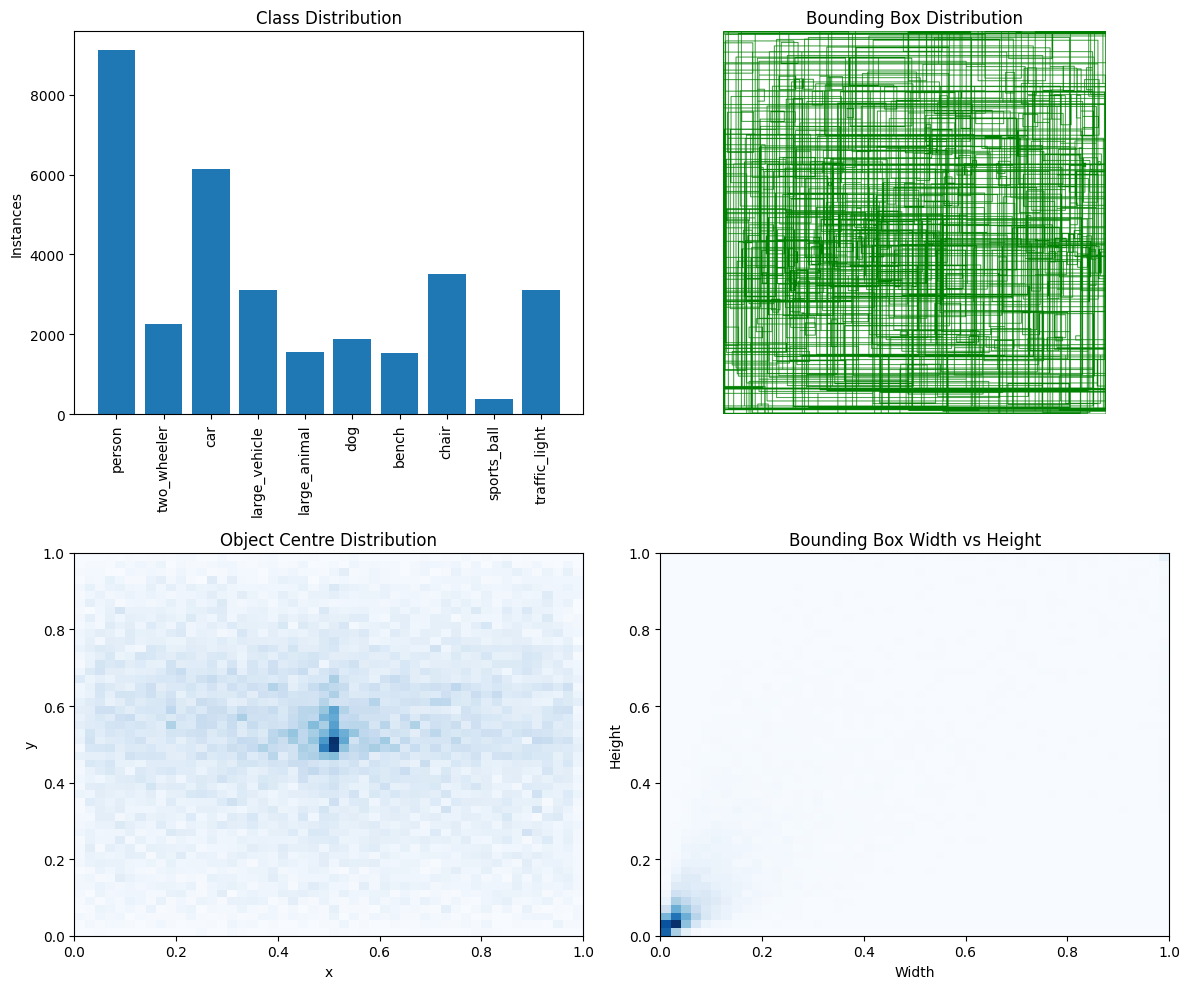

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/dataset_analysis.jpg


In [ ]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)")

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = DATASET_DIR

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)

In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Hazard_Detection")

for item in BASE_DIR.rglob("*"):
    print(item)

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5eebaa370bdebd6067d1c.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef54a370bdebd608dcdb.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef7ea370bdebd609781e.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef59a370bdebd608f40a.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef38a370bdebd60870ee.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef39a370bdebd6087530.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5eec2a370bdebd60697c3.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/images/train/coco_6af5ef2aa370bdebd608366e.jpg
/content/driv

In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Hazard_Detection")

yaml_files = list(BASE_DIR.rglob("data.yaml"))

print("Found data.yaml files:")

for file in yaml_files:
    print(file)

Found data.yaml files:
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset (1)/data.yaml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/data.yaml


In [4]:
from pathlib import Path
import yaml

# CHANGE THIS to your dataset folder
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset")

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print("Current data.yaml:")
print(yaml.dump(data, sort_keys=False))

print("\nExisting classes:")
old_names = data["names"]

if isinstance(old_names, list):
    old_names = dict(enumerate(old_names))

for class_id, class_name in old_names.items():
    print(f"{class_id}: {class_name}")

Current data.yaml:
path: /content/drive/MyDrive/Hazard_Dataset/raw_datasets/coco_dataset
train: images/train
val: images/val
test: images/test
names:
  0: person
  1: two_wheeler
  2: car
  3: large_vehicle
  4: large_animal
  5: dog
  6: bench
  7: chair
  8: sports_ball
  9: traffic_light


Existing classes:
0: person
1: two_wheeler
2: car
3: large_vehicle
4: large_animal
5: dog
6: bench
7: chair
8: sports_ball
9: traffic_light


In [5]:
# Master class IDs
master_classes = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "open_drain",
    9: "speed_breaker",
    10: "stairs_up",
    11: "stairs_down",
    12: "curb_or_step",
    13: "obstacle",
    14: "vendor_stall",
    15: "bench",
    16: "chair",
    17: "door",
    18: "sports_balls",
    19: "traffic_lights",
    20: "other_hazards"
}

# Source class name -> master class ID
class_mapping = {
    "person": 0,

    "bicycle": 1,
    "scooter": 1,
    "motorcycle": 1,
    "motorbike": 1,

    "car": 2,

    "auto": 3,
    "auto_rickshaw": 3,
    "autorickshaw": 3,
    "e_rickshaw": 3,

    "bus": 4,
    "truck": 4,
    "tractor": 4,
    "tractors": 4,
    "large_vehicle": 4,

    "cow": 5,
    "cattle": 5,
    "horse": 5,

    "dog": 6,

    "pothole": 7,
    "broken_pavement": 7,

    "open_drain": 8,
    "speed_breaker": 9,
    "speed_bump": 9,

    "stairs_up": 10,
    "stairs_down": 11,

    "curb": 12,
    "curb_or_step": 12,
    "step": 12,

    "barricade": 13,
    "pull_cart": 13,
    "pull-cart": 13,
    "pulley_cart": 13,
    "trash_can": 13,
    "trash_cans": 13,
    "garbage_bin": 13,
    "cement_machinery": 13,

    "vendor_stall": 14,
    "bench": 15,
    "chair": 16,
    "door": 17,

    "sports_ball": 18,
    "sports_balls": 18,

    "traffic_light": 19,
    "traffic_lights": 19
}

# Normalize names for matching
def normalize(name):
    return str(name).lower().strip().replace(" ", "_")

# Build old ID -> master ID mapping
old_to_new = {}

for old_id, old_name in old_names.items():
    normalized_name = normalize(old_name)

    if normalized_name in class_mapping:
        old_to_new[int(old_id)] = class_mapping[normalized_name]

    else:
        print(f"UNMAPPED: {old_id} -> {old_name}")

print("\nClass ID mapping:")
for old_id, new_id in old_to_new.items():
    print(f"{old_id} -> {new_id} ({master_classes[new_id]})")

UNMAPPED: 1 -> two_wheeler
UNMAPPED: 4 -> large_animal

Class ID mapping:
0 -> 0 (person)
2 -> 2 (car)
3 -> 4 (large_vehicle)
5 -> 6 (dog)
6 -> 15 (bench)
7 -> 16 (chair)
8 -> 18 (sports_balls)
9 -> 19 (traffic_lights)


In [7]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import yaml
import shutil

# ==========================================
# 1. DATASET PATH
# ==========================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset"
)

yaml_path = DATASET_DIR / "data.yaml"

# ==========================================
# 2. READ EXISTING DATA.YAML
# ==========================================

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

old_names = data["names"]

if isinstance(old_names, list):
    old_names = dict(enumerate(old_names))

print("EXISTING CLASSES:")
for class_id, class_name in old_names.items():
    print(f"{class_id}: {class_name}")

# ==========================================
# 3. MASTER CLASSES
# ==========================================

master_classes = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "open_drain",
    9: "speed_breaker",
    10: "stairs_up",
    11: "stairs_down",
    12: "curb_or_step",
    13: "obstacle",
    14: "vendor_stall",
    15: "bench",
    16: "chair",
    17: "door",
    18: "sports_balls",
    19: "traffic_lights",
    20: "other_hazards"
}

# ==========================================
# 4. SOURCE CLASS -> MASTER CLASS MAPPING
# ==========================================

class_mapping = {
    "person": 0,
    "two_wheeler": 1,
    "bicycle": 1,
    "scooter": 1,
    "motorcycle": 1,

    "car": 2,

    "auto": 3,
    "auto_rickshaw": 3,
    "e_rickshaw": 3,

    "bus": 4,
    "truck": 4,
    "tractor": 4,
    "large_vehicle": 4,

    "cow": 5,
    "cattle": 5,
    "horse": 5,
    "large_animal": 5,

    "dog": 6,

    "pothole": 7,
    "broken_pavement": 7,

    "open_drain": 8,
    "speed_breaker": 9,
    "speed_bump": 9,

    "stairs_up": 10,
    "stairs_down": 11,

    "curb": 12,
    "step": 12,
    "curb_or_step": 12,

    "barricade": 13,
    "pull_cart": 13,
    "pull-cart": 13,
    "trash_can": 13,
    "trash_cans": 13,
    "cement_machinery": 13,

    "vendor_stall": 14,
    "bench": 15,
    "chair": 16,
    "door": 17,

    "sports_ball": 18,
    "sports_balls": 18,

    "traffic_light": 19,
    "traffic_lights": 19
}

def normalize(name):
    return str(name).lower().strip().replace(" ", "_")

# Create old ID -> master ID mapping
old_to_new = {}

for old_id, old_name in old_names.items():

    normalized_name = normalize(old_name)

    if normalized_name in class_mapping:
        old_to_new[int(old_id)] = class_mapping[normalized_name]

    else:
        print(f"UNMAPPED CLASS: {old_id} -> {old_name}")

print("\nGENERATED CLASS MAPPING:")

for old_id, new_id in old_to_new.items():
    print(
        f"{old_id} -> {new_id} "
        f"({master_classes[new_id]})"
    )

# ==========================================
# 5. FIND ALL LABEL FOLDERS
# ==========================================

label_dirs = [
    p for p in DATASET_DIR.rglob("labels")
    if p.is_dir()
]

print("\nLABEL FOLDERS FOUND:")

for folder in label_dirs:
    print(folder)

if not label_dirs:
    raise ValueError("No labels folders found!")

# ==========================================
# 6. CHECK ALL ANNOTATION CLASS IDS
# ==========================================

unmapped_ids = set()

for label_dir in label_dirs:

    for txt_file in label_dir.rglob("*.txt"):

        with open(txt_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if not parts:
                    continue

                class_id = int(float(parts[0]))

                if class_id not in old_to_new:
                    unmapped_ids.add(class_id)

if unmapped_ids:
    raise ValueError(
        f"Unmapped annotation IDs: {sorted(unmapped_ids)}"
    )

print("\nAll annotation IDs have valid mappings!")

# ==========================================
# 7. BACKUP AND REMAP ANNOTATIONS
# ==========================================

modified_files = 0

for label_dir in label_dirs:

    for txt_file in label_dir.rglob("*.txt"):

        # Backup original file
        backup_file = txt_file.with_suffix(".txt.bak")

        if not backup_file.exists():
            shutil.copy2(txt_file, backup_file)

        new_lines = []

        with open(txt_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if not parts:
                    continue

                old_id = int(float(parts[0]))
                new_id = old_to_new[old_id]

                # Change only class ID
                parts[0] = str(new_id)

                new_lines.append(" ".join(parts))

        with open(txt_file, "w") as f:
            f.write("\n".join(new_lines))

        modified_files += 1

print(f"\nSuccessfully remapped {modified_files} files!")

# ==========================================
# 8. UPDATE DATA.YAML
# ==========================================

data["nc"] = len(master_classes)
data["names"] = master_classes

with open(yaml_path, "w") as f:

    yaml.safe_dump(
        data,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("\nUPDATED DATA.YAML:")
with open(yaml_path, "r") as f:
    print(f.read())

# ==========================================
# 9. FINAL SUMMARY
# ==========================================

print("\n========== REMAPPING COMPLETE ==========")
print(f"Original classes: {len(old_names)}")
print(f"Master classes: {len(master_classes)}")
print(f"Annotation files modified: {modified_files}")
print(f"Backups created alongside original labels")
print("Images were NOT modified or duplicated.")
print("========================================")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EXISTING CLASSES:
0: person
1: two_wheeler
2: car
3: large_vehicle
4: large_animal
5: dog
6: bench
7: chair
8: sports_ball
9: traffic_light

GENERATED CLASS MAPPING:
0 -> 0 (person)
1 -> 1 (two_wheeler)
2 -> 2 (car)
3 -> 4 (large_vehicle)
4 -> 5 (large_animal)
5 -> 6 (dog)
6 -> 15 (bench)
7 -> 16 (chair)
8 -> 18 (sports_balls)
9 -> 19 (traffic_lights)

LABEL FOLDERS FOUND:
/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/labels

All annotation IDs have valid mappings!

Successfully remapped 8695 files!

UPDATED DATA.YAML:
path: /content/drive/MyDrive/Hazard_Dataset/raw_datasets/coco_dataset
train: images/train
val: images/val
test: images/test
names:
  0: person
  1: two_wheeler
  2: car
  3: auto_rickshaw
  4: large_vehicle
  5: large_animal
  6: dog
  7: pothole
  8: open_drain
  9: speed_breaker
  10: stairs_up
  11: stairs_down
  12: curb

In [8]:
from pathlib import Path

label_dir = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/labels"
)

files = list(label_dir.rglob("*.txt"))

print("Total annotation files:", len(files))
print("Total size (MB):", round(
    sum(f.stat().st_size for f in files) / (1024 * 1024), 2
))

Total annotation files: 8695
Total size (MB): 1.18
